# Step 05: feature engineering

Builds the flat patient-hour feature table for the SIRS rule, logistic regression and LightGBM, and checks it.

## Setup

Imports, paths, feature names and helpers.

In [1]:
import json
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import roc_auc_score
from tqdm import tqdm

SEED = 42

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10, "legend.frameon": False})

COL_SEPTIC, COL_CONTROL = "#d1495b", "#2e86ab"


def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "dataset").is_dir():
            return folder
    raise FileNotFoundError(f"no folder containing a 'dataset' directory above {start}")


ROOT = find_root()
PROC = ROOT / "data" / "processed"
TAB = ROOT / "results" / "tables"
FIG = ROOT / "results" / "figures"
for folder in (PROC, TAB, FIG):
    folder.mkdir(parents=True, exist_ok=True)

UNSCALED_PATH = PROC / "pre_unscaled.parquet"
SCALED_PATH = PROC / "pre_scaled.parquet"
FEATURES_PATH = PROC / "features_flat.parquet"
SETS_PATH = PROC / "feature_sets.json"

SUMMARY = []
SAVED = []


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" ({detail})" if detail else ""))


def fmt(x):
    return f"{x:,}" if isinstance(x, (int, np.integer)) else f"{x:,.2f}"


def expect(label, observed, expected, tol=0):
    check(label, abs(observed - expected) <= tol, f"observed {fmt(observed)}, expected {fmt(expected)}")


@contextmanager
def guarded(label):
    # an exception inside a check block becomes a failed check
    try:
        yield
    except Exception as exc:
        check(label, False, f"exception {type(exc).__name__}: {exc}")


@contextmanager
def timed(label):
    t0 = time.perf_counter()
    yield
    log(f"elapsed, {label}: {time.perf_counter() - t0:.1f} s")


def save_fig(name, top=None):
    plt.tight_layout(rect=(0, 0, 1, top) if top else None)
    path = FIG / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    SAVED.append(path)
    plt.show()
    plt.close("all")


def file_mb(path):
    return path.stat().st_size / 1e6


def read_col(path, name):
    return pq.read_table(path, columns=[name]).column(0).to_numpy()


groups_json = json.loads((PROC / "column_groups.json").read_text())
VITALS, LABS = groups_json["vitals"], groups_json["labs"]
TARGET = groups_json["target"][0] if isinstance(groups_json["target"], list) else groups_json["target"]
VALUE_COLS = VITALS + LABS

CHUNK_ROWS = 190_000
WINDOWS = (6, 12)
ROLL_STATS = ("mean", "std", "min", "max")
SPLIT_DTYPE = pd.CategoricalDtype(["train", "val", "test"])

ID_COLS = ["patient_id", "hospital", "hour", "split"]
MASK_COLS = [f"{c}_m" for c in VALUE_COLS]
TSL_COLS = [f"{c}_tsl" for c in VALUE_COLS]
CNT_COLS = [f"cnt_{c}" for c in VALUE_COLS]
AGG_COLS = ["n_labs_now", "n_labs_last6", "n_labs_so_far"]
ROLL_COLS = [f"{v}_{s}{w}" for v in VITALS for w in WINDOWS for s in ROLL_STATS]
DELTA_COLS = [f"{v}_delta6" for v in VITALS]
CLIN_SOURCES = {
    "shock_index": ["HR", "SBP"], "pulse_pressure": ["SBP", "DBP"], "bun_creat_ratio": ["BUN", "Creatinine"],
    "sirs_temp": ["Temp"], "sirs_hr": ["HR"], "sirs_resp": ["Resp"], "sirs_wbc": ["WBC"],
    "sirs_count": ["Temp", "HR", "Resp", "WBC"],
}
CLIN_COLS = list(CLIN_SOURCES)
EXTREME_SPECS = [
    ("HR_max_so_far", "HR", "max"), ("Resp_max_so_far", "Resp", "max"), ("Temp_max_so_far", "Temp", "max"),
    ("Temp_min_so_far", "Temp", "min"), ("MAP_min_so_far", "MAP", "min"), ("SBP_min_so_far", "SBP", "min"),
    ("O2Sat_min_so_far", "O2Sat", "min"), ("Lactate_max_so_far", "Lactate", "max"),
    ("Creatinine_max_so_far", "Creatinine", "max"), ("Bilirubin_total_max_so_far", "Bilirubin_total", "max"),
    ("Platelets_min_so_far", "Platelets", "min"), ("WBC_max_so_far", "WBC", "max"), ("WBC_min_so_far", "WBC", "min"),
]
EXTREME_COLS = [name for name, _, _ in EXTREME_SPECS]
STATIC_COLS = ["Age", "Gender", "unit_1", "unit_2", "unit_unknown", "HospAdmTime", "ICULOS"]

FEATURES = (VALUE_COLS + MASK_COLS + TSL_COLS + CNT_COLS + AGG_COLS + ROLL_COLS + DELTA_COLS + CLIN_COLS
            + EXTREME_COLS + STATIC_COLS)
INPUT_COLS = ID_COLS + VALUE_COLS + MASK_COLS + TSL_COLS + STATIC_COLS + [TARGET]
OUT_COLS = ID_COLS + FEATURES + [TARGET]

SPLIT_NAMES = ("train", "val", "test")
KNOWN_SPLITS = {"train": (28235, 1085958), "val": (6050, 234037), "test": (6051, 232215)}

log(f"project root: {ROOT.name}")
log(f"features defined: {len(FEATURES)}, output columns: {len(OUT_COLS)}")
check("feature count is 239 and names are unique", len(FEATURES) == 239 and len(set(FEATURES)) == 239)

project root: Sepsis_ml
features defined: 239, output columns: 244
[PASS] feature count is 239 and names are unique


## Input checks

The input is read in chunks of whole patients.

In [2]:
def iter_patient_chunks(path, columns, chunk_rows=CHUNK_ROWS):
    carry = None
    for batch in pq.ParquetFile(path).iter_batches(batch_size=chunk_rows, columns=columns):
        part = batch.to_pandas()
        if carry is not None:
            part = pd.concat([carry, part], ignore_index=True)
        ids = part["patient_id"].to_numpy()
        differs = np.flatnonzero(ids != ids[-1])
        cut = int(differs.max()) + 1 if len(differs) else 0
        carry = part.iloc[cut:]
        if cut > 0:
            yield part.iloc[:cut].reset_index(drop=True)
    if carry is not None and len(carry) > 0:
        yield carry.reset_index(drop=True)


pf_in = pq.ParquetFile(UNSCALED_PATH)
N = pf_in.metadata.num_rows
expect("input rows", N, 1552210)
expect("input columns", pf_in.metadata.num_columns, 114)
check("input column order", pf_in.schema_arrow.names == INPUT_COLS)

stream_cols = ["patient_id", "hour", "split", TARGET] + VALUE_COLS + MASK_COLS
ids_list, len_list = [], []
rows_per_split = dict.fromkeys(SPLIT_NAMES, 0)
patients_per_split = dict.fromkeys(SPLIT_NAMES, 0)
n_positive = n_bad_hour = n_nan_after_obs = n_value_before_obs = 0

with timed("input stream checks"):
    n_chunks = int(np.ceil(N / CHUNK_ROWS))
    for chunk in tqdm(iter_patient_chunks(UNSCALED_PATH, stream_cols), total=n_chunks, desc="input chunks"):
        ids = chunk["patient_id"].to_numpy()
        change = np.r_[True, ids[1:] != ids[:-1]]
        starts = np.flatnonzero(change)
        lens = np.diff(np.r_[starts, len(chunk)])
        ids_list.append(ids[starts])
        len_list.append(lens)

        n_bad_hour += int((chunk["hour"].to_numpy() != np.arange(len(chunk)) - np.repeat(starts, lens)).sum())
        n_positive += int((chunk[TARGET] == 1).sum())
        split_values = chunk["split"].to_numpy()
        for name in SPLIT_NAMES:
            rows_per_split[name] += int((split_values == name).sum())
            patients_per_split[name] += int((split_values[starts] == name).sum())

        seen = chunk[MASK_COLS].groupby(np.cumsum(change) - 1).cummax().to_numpy()
        is_nan = chunk[VALUE_COLS].isna().to_numpy()
        n_nan_after_obs += int((is_nan & (seen == 1)).sum())
        n_value_before_obs += int((~is_nan & (seen == 0)).sum())

order_ids = np.concatenate(ids_list)
run_len = np.concatenate(len_list)
n_patients = len(order_ids)
patient_start = np.r_[0, np.cumsum(run_len)[:-1]]
patient_end = patient_start + run_len
patient_codes = np.repeat(np.arange(n_patients), run_len)
log(f"patients: {n_patients:,}, chunks: {len(len_list)}, rows per patient {run_len.min()} to {run_len.max()} (median {np.median(run_len):.0f})")

splits_table = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": "string", "hospital": "string"})
expected_order = splits_table.sort_values(["hospital", "patient_id"])["patient_id"].to_numpy()
check("patients appear once each, ordered by hospital and patient_id", np.array_equal(order_ids, expected_order), f"{n_patients:,} patients")
check("block lengths match n_rows in patient_splits.csv", np.array_equal(run_len, splits_table.set_index("patient_id").loc[order_ids, "n_rows"].to_numpy()))
check("hour equals the row position within each patient", n_bad_hour == 0, f"{n_bad_hour:,} violations")
for name in SPLIT_NAMES:
    expect(f"{name} patients", patients_per_split[name], KNOWN_SPLITS[name][0])
    expect(f"{name} rows", rows_per_split[name], KNOWN_SPLITS[name][1])
expect("positive rows", n_positive, 27916)
check("value is NaN only where mask = 0 or nothing observed yet", n_nan_after_obs == 0 and n_value_before_obs == 0,
      f"{n_nan_after_obs:,} NaN after an observation, {n_value_before_obs:,} values before the first observation")

[PASS] input rows (observed 1,552,210, expected 1,552,210)
[PASS] input columns (observed 114, expected 114)
[PASS] input column order


input chunks: 11it [00:01,  6.83it/s]                      


elapsed, input stream checks: 1.6 s
patients: 40,336, chunks: 11, rows per patient 8 to 336 (median 38)
[PASS] patients appear once each, ordered by hospital and patient_id (40,336 patients)
[PASS] block lengths match n_rows in patient_splits.csv
[PASS] hour equals the row position within each patient (0 violations)
[PASS] train patients (observed 28,235, expected 28,235)
[PASS] train rows (observed 1,085,958, expected 1,085,958)
[PASS] val patients (observed 6,050, expected 6,050)
[PASS] val rows (observed 234,037, expected 234,037)
[PASS] test patients (observed 6,051, expected 6,051)
[PASS] test rows (observed 232,215, expected 232,215)
[PASS] positive rows (observed 27,916, expected 27,916)
[PASS] value is NaN only where mask = 0 or nothing observed yet (0 NaN after an observation, 0 values before the first observation)


## Feature function

Everything is vectorised and looks only at the current and earlier rows of the same patient.

In [3]:
def rolling_block(x, hour):
    x = x.astype("float64")
    out = {}
    for w in WINDOWS:
        win = sliding_window_view(np.concatenate([np.full(w - 1, np.nan), x]), w).copy()
        win[np.arange(w)[None, :] < (w - 1 - hour)[:, None]] = np.nan
        n_obs = np.sum(~np.isnan(win), axis=1)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            res = {"mean": np.nanmean(win, axis=1), "std": np.nanstd(win, axis=1, ddof=1),
                   "min": np.nanmin(win, axis=1), "max": np.nanmax(win, axis=1)}
        res["std"][n_obs < 2] = np.nan
        for stat in ROLL_STATS:
            out[(stat, w)] = res[stat]
    return out


def build_features(chunk):
    n = len(chunk)
    rowpos = np.arange(n)
    hour = chunk["hour"].to_numpy().astype("int64")
    start = rowpos - hour

    vals = chunk[VALUE_COLS].to_numpy(dtype="float32")
    masks = chunk[MASK_COLS].to_numpy()
    tsl = chunk[TSL_COLS].to_numpy()
    vidx = {c: i for i, c in enumerate(VALUE_COLS)}
    lab_idx = [vidx[c] for c in LABS]

    # cumulative counts within patient
    cs = np.zeros((n + 1, len(VALUE_COLS)), dtype=np.int32)
    np.cumsum(masks, axis=0, dtype=np.int32, out=cs[1:])
    cnt = (cs[1:] - cs[start]).astype("int16")
    n_now = masks[:, lab_idx].sum(axis=1, dtype=np.int32)
    cs_now = np.r_[0, np.cumsum(n_now)]
    n_last6 = cs_now[rowpos + 1] - cs_now[np.maximum(rowpos - 5, start)]
    n_so_far = cnt[:, lab_idx].sum(axis=1, dtype=np.int32)

    data = {
        "patient_id": chunk["patient_id"], "hospital": chunk["hospital"], "hour": chunk["hour"],
        "split": chunk["split"].astype(SPLIT_DTYPE),
    }
    for i, c in enumerate(VALUE_COLS):
        data[c] = vals[:, i]
    for i, c in enumerate(MASK_COLS):
        data[c] = masks[:, i]
    for i, c in enumerate(TSL_COLS):
        data[c] = tsl[:, i]
    for i, c in enumerate(CNT_COLS):
        data[c] = cnt[:, i]
    data["n_labs_now"] = n_now.astype("int16")
    data["n_labs_last6"] = n_last6.astype("int16")
    data["n_labs_so_far"] = n_so_far.astype("int16")

    for v in VITALS:
        rolled = rolling_block(vals[:, vidx[v]], hour)
        for w in WINDOWS:
            for stat in ROLL_STATS:
                data[f"{v}_{stat}{w}"] = rolled[(stat, w)].astype("float32")

    for v in VITALS:
        x = vals[:, vidx[v]]
        shifted = np.full(n, np.nan, dtype="float32")
        shifted[6:] = x[:-6]
        delta = x - shifted
        delta[hour < 6] = np.nan
        data[f"{v}_delta6"] = delta

    hr, sbp, dbp, bun, creat = (vals[:, vidx[c]] for c in ("HR", "SBP", "DBP", "BUN", "Creatinine"))
    temp, resp, wbc = (vals[:, vidx[c]] for c in ("Temp", "Resp", "WBC"))
    with np.errstate(divide="ignore", invalid="ignore"):
        data["shock_index"] = np.where(sbp > 0, hr / sbp, np.nan).astype("float32")
        data["pulse_pressure"] = (sbp - dbp).astype("float32")
        data["bun_creat_ratio"] = np.where(creat > 0, bun / creat, np.nan).astype("float32")
    flags = {
        "sirs_temp": (temp > 38) | (temp < 36), "sirs_hr": hr > 90, "sirs_resp": resp > 20, "sirs_wbc": (wbc > 12) | (wbc < 4),
    }
    for name, flag in flags.items():
        data[name] = flag.astype("int8")
    data["sirs_count"] = sum(flag.astype("int8") for flag in flags.values()).astype("int8")

    for name, col, how in EXTREME_SPECS:
        grouped = pd.Series(vals[:, vidx[col]]).groupby(start)
        data[name] = (grouped.cummax() if how == "max" else grouped.cummin()).to_numpy()

    data["Age"] = chunk["Age"].to_numpy()
    for c in ("Gender", "unit_1", "unit_2", "unit_unknown"):
        data[c] = chunk[c].to_numpy()
    data["HospAdmTime"] = chunk["HospAdmTime"].to_numpy()
    data["ICULOS"] = chunk["ICULOS"].to_numpy()
    data[TARGET] = chunk[TARGET]

    out = pd.DataFrame(data)
    return out[OUT_COLS]

## Build and write

Each chunk is appended to the parquet file as it is built.

In [4]:
writer = None
schema = None
n_written = 0
try:
    with timed("feature build and write"):
        for chunk in tqdm(iter_patient_chunks(UNSCALED_PATH, INPUT_COLS), total=n_chunks, desc="feature chunks"):
            feats = build_features(chunk)
            if writer is None:
                table = pa.Table.from_pandas(feats, preserve_index=False)
                schema = table.schema
                writer = pq.ParquetWriter(FEATURES_PATH, schema)
            else:
                table = pa.Table.from_pandas(feats, schema=schema, preserve_index=False)
            writer.write_table(table)
            n_written += len(feats)
finally:
    if writer is not None:
        writer.close()
SAVED.append(FEATURES_PATH)

pf_out = pq.ParquetFile(FEATURES_PATH)
expect("rows written", pf_out.metadata.num_rows, 1552210)
expect("columns written", pf_out.metadata.num_columns, 244)
check("output column names and order", pf_out.schema_arrow.names == OUT_COLS)

types = {f.name: f.type for f in pf_out.schema_arrow}
int16_cols = TSL_COLS + CNT_COLS + AGG_COLS
int8_cols = ["sirs_temp", "sirs_hr", "sirs_resp", "sirs_wbc", "sirs_count", "Gender", "unit_1", "unit_2", "unit_unknown"]
float_cols = [c for c in FEATURES if c not in int16_cols + int8_cols + MASK_COLS]
wrong = [c for c in float_cols if types[c] != pa.float32()] + [c for c in int16_cols if types[c] != pa.int16()] \
    + [c for c in int8_cols if types[c] != pa.int8()] + [c for c in MASK_COLS if types[c] != pa.uint8()]
check("feature dtypes (float32, int16, int8, uint8 masks)", not wrong, ", ".join(wrong[:5]))
log(f"{FEATURES_PATH.relative_to(ROOT)}: {file_mb(FEATURES_PATH):.1f} MB, {pf_out.metadata.num_row_groups} row groups")

feature chunks: 11it [00:17,  1.60s/it]                      

elapsed, feature build and write: 17.6 s
[PASS] rows written (observed 1,552,210, expected 1,552,210)
[PASS] columns written (observed 244, expected 244)
[PASS] output column names and order
[PASS] feature dtypes (float32, int16, int8, uint8 masks)
data/processed/features_flat.parquet: 184.2 MB, 11 row groups


## Feature catalog

In [5]:
def source_type(cols):
    kinds = {"vital" if c in VITALS else "lab" if c in LABS else "static" for c in cols}
    return kinds.pop() if len(kinds) == 1 else "mixed"


catalog_rows = []


def add(feature, group, sources, missingness=False):
    catalog_rows.append({
        "feature": feature, "group": group, "source_vars": ";".join(sources), "source_type": source_type(sources),
        "missingness_info": missingness, "icu_time": feature in ("ICULOS", "HospAdmTime"),
    })


for c in VALUE_COLS:
    add(c, "value", [c])
for c in VALUE_COLS:
    add(f"{c}_m", "mask", [c], True)
for c in VALUE_COLS:
    add(f"{c}_tsl", "time_since", [c], True)
for c in VALUE_COLS:
    add(f"cnt_{c}", "count", [c], True)
for name in AGG_COLS:
    add(name, "missingness_agg", LABS, True)
for v in VITALS:
    for w in WINDOWS:
        for s in ROLL_STATS:
            add(f"{v}_{s}{w}", "rolling", [v])
for v in VITALS:
    add(f"{v}_delta6", "trend", [v])
for name, sources in CLIN_SOURCES.items():
    add(name, "clinical", sources)
for name, col, _ in EXTREME_SPECS:
    add(name, "extreme", [col])
for c in STATIC_COLS:
    add(c, "static", [c])

catalog = pd.DataFrame(catalog_rows)
catalog_path = TAB / "feature_catalog.csv"
catalog.to_csv(catalog_path, index=False)
SAVED.append(catalog_path)

GROUP_OF = dict(zip(catalog["feature"], catalog["group"]))
log("features per group")
log(catalog["group"].value_counts().reindex(["value", "mask", "time_since", "count", "missingness_agg", "rolling", "trend",
                                             "clinical", "extreme", "static"]).to_string())
expect("total features in the catalog", len(catalog), 239)
check("feature names are unique", catalog["feature"].is_unique)
check("catalog matches the parquet columns", catalog["feature"].tolist() == [c for c in pf_out.schema_arrow.names if c in set(FEATURES)]
      and catalog["feature"].tolist() == FEATURES)
catalog.head(3)

features per group
group
value              34
mask               34
time_since         34
count              34
missingness_agg     3
rolling            64
trend               8
clinical            8
extreme            13
static              7
[PASS] total features in the catalog (observed 239, expected 239)
[PASS] feature names are unique
[PASS] catalog matches the parquet columns


,feature,group,source_vars,source_type,missingness_info,icu_time
0,HR,value,HR,vital,False,False
1,O2Sat,value,O2Sat,vital,False,False
2,Temp,value,Temp,vital,False,False


## Feature sets

Lists of feature names for the later ablations.

In [6]:
feature_sets = {
    "all": FEATURES,
    "no_missingness": catalog.loc[~catalog["missingness_info"], "feature"].tolist(),
    "no_icu_time": catalog.loc[~catalog["icu_time"], "feature"].tolist(),
    "vitals_only": catalog.loc[catalog["source_type"].isin(["vital", "static"]), "feature"].tolist(),
    "raw_values": VALUE_COLS + STATIC_COLS,
    "raw_values_with_missingness": VALUE_COLS + MASK_COLS + TSL_COLS + STATIC_COLS,
}
SETS_PATH.write_text(json.dumps(feature_sets, indent=1))
SAVED.append(SETS_PATH)
for name, members in feature_sets.items():
    log(f"feature set {name}: {len(members)} features")
check("all feature set members exist in the table", all(set(m) <= set(FEATURES) for m in feature_sets.values()))

feature set all: 239 features
feature set no_missingness: 134 features
feature set no_icu_time: 237 features
feature set vitals_only: 123 features
feature set raw_values: 41 features
feature set raw_values_with_missingness: 109 features
[PASS] all feature set members exist in the table


## Verification

Each check runs on its own, so a failure is logged and the rest still runs.

In [7]:
def count_mismatches(a, b):
    total = 0
    for col in a.columns:
        x, y = a[col].to_numpy(), b[col].to_numpy()
        if x.dtype.kind == "f":
            total += int((~np.isclose(x, y, rtol=1e-5, atol=1e-6, equal_nan=True)).sum())
        else:
            total += int((x != y).sum())
    return total


def read_patients(path, ids, columns=None):
    return pd.read_parquet(path, columns=columns, filters=[("patient_id", "in", [str(i) for i in ids])])


check_rng = np.random.default_rng(SEED)

log("a. causality test")
with guarded("causality test"), timed("causality test"):
    picked = np.sort(check_rng.choice(n_patients, size=min(300, n_patients), replace=False))
    cut_at = dict(zip(order_ids[picked], check_rng.integers(8, run_len[picked] + 1)))
    inputs = read_patients(UNSCALED_PATH, order_ids[picked])
    stored = read_patients(FEATURES_PATH, order_ids[picked])
    keep = inputs["hour"].to_numpy() < inputs["patient_id"].map(cut_at).to_numpy()
    cut_input = inputs.loc[keep].reset_index(drop=True)
    reference = stored.loc[keep].reset_index(drop=True)
    rebuilt = build_features(cut_input)
    n_mismatch = count_mismatches(rebuilt, reference)
    check("features of cut-off patients equal the full-table features", n_mismatch == 0,
          f"{n_mismatch:,} mismatching cells of {rebuilt.size:,}, {len(rebuilt):,} rows from {len(picked)} patients")
    del inputs, stored, cut_input, reference, rebuilt

log("b. plain pandas reference for rolling statistics and delta6")
with guarded("pandas reference check"), timed("pandas reference check"):
    picked = np.sort(check_rng.choice(n_patients, size=min(200, n_patients), replace=False))
    inputs = read_patients(UNSCALED_PATH, order_ids[picked], ["patient_id", "hour"] + VITALS).reset_index(drop=True)
    stored = read_patients(FEATURES_PATH, order_ids[picked], ["patient_id", "hour"] + ROLL_COLS + DELTA_COLS).reset_index(drop=True)
    check("same rows in both reads", inputs[["patient_id", "hour"]].equals(stored[["patient_id", "hour"]]))
    n_bad = n_cells = 0
    for _, g in inputs.groupby("patient_id", sort=False):
        pos = g.index.to_numpy()
        for v in VITALS:
            s = g[v]
            expected = {}
            for w in WINDOWS:
                expected[f"{v}_mean{w}"] = s.rolling(w, min_periods=1).mean()
                expected[f"{v}_std{w}"] = s.rolling(w, min_periods=2).std()
                expected[f"{v}_min{w}"] = s.rolling(w, min_periods=1).min()
                expected[f"{v}_max{w}"] = s.rolling(w, min_periods=1).max()
            expected[f"{v}_delta6"] = s - s.shift(6)
            for col, e in expected.items():
                got = stored[col].to_numpy()[pos]
                n_bad += int((~np.isclose(got, e.to_numpy(), rtol=1e-4, atol=1e-4, equal_nan=True)).sum())
                n_cells += len(pos)
    check("rolling mean, std, min, max and delta6 match the pandas reference", n_bad == 0, f"{n_bad:,} mismatches in {n_cells:,} cells, {len(picked)} patients")
    del inputs, stored

a. causality test
[PASS] features of cut-off patients equal the full-table features (0 mismatching cells of 1,726,544, 7,076 rows from 300 patients)
elapsed, causality test: 3.8 s
b. plain pandas reference for rolling statistics and delta6
[PASS] same rows in both reads
[PASS] rolling mean, std, min, max and delta6 match the pandas reference (0 mismatches in 598,248 cells, 200 patients)
elapsed, pandas reference check: 1.5 s


In [8]:
log("c. counts")
with guarded("count checks"), timed("count checks"):
    hour_all = read_col(FEATURES_PATH, "hour").astype("int64")
    n_bad_cnt = n_bad_last = 0
    lab_cnt_sum = np.zeros(N, dtype=np.int32)
    lab_now = np.zeros(N, dtype=np.int32)
    for col in VALUE_COLS:
        m = read_col(FEATURES_PATH, f"{col}_m")
        cnt = read_col(FEATURES_PATH, f"cnt_{col}")
        n_bad_cnt += int((cnt != pd.Series(m).groupby(patient_codes).cumsum().to_numpy()).sum())
        n_bad_last += int((cnt[patient_end - 1] != np.add.reduceat(m.astype("int32"), patient_start)).sum())
        if col in LABS:
            lab_cnt_sum += cnt
            lab_now += m
    check("cnt equals the cumulative sum of the mask", n_bad_cnt == 0, f"{n_bad_cnt:,} violations")
    check("last-row cnt equals the number of measured hours", n_bad_last == 0, f"{n_bad_last:,} patients differ")
    check("n_labs_so_far equals the sum of the lab cnt columns", bool((read_col(FEATURES_PATH, "n_labs_so_far") == lab_cnt_sum).all()))
    check("n_labs_now equals the sum of the lab masks", bool((read_col(FEATURES_PATH, "n_labs_now") == lab_now).all()))
    ref_last6 = lab_now.copy()
    for j in range(1, 6):
        shifted = np.zeros(N, dtype=np.int32)
        shifted[j:] = lab_now[:-j]
        ref_last6 += np.where(hour_all >= j, shifted, 0)
    check("n_labs_last6 equals the sum of the last 6 rows", bool((read_col(FEATURES_PATH, "n_labs_last6") == ref_last6).all()))
    del lab_cnt_sum, lab_now, ref_last6

log("d. clinical features")
with guarded("clinical feature check"), timed("clinical feature check"):
    sample = np.sort(check_rng.choice(N, size=min(200_000, N), replace=False))
    src = {c: read_col(UNSCALED_PATH, c)[sample].astype("float64") for c in ("HR", "SBP", "DBP", "BUN", "Creatinine", "Temp", "Resp", "WBC")}
    with np.errstate(divide="ignore", invalid="ignore"):
        ref = {
            "shock_index": np.where(src["SBP"] > 0, src["HR"] / src["SBP"], np.nan),
            "pulse_pressure": src["SBP"] - src["DBP"],
            "bun_creat_ratio": np.where(src["Creatinine"] > 0, src["BUN"] / src["Creatinine"], np.nan),
            "sirs_temp": ((src["Temp"] > 38) | (src["Temp"] < 36)).astype(int),
            "sirs_hr": (src["HR"] > 90).astype(int),
            "sirs_resp": (src["Resp"] > 20).astype(int),
            "sirs_wbc": ((src["WBC"] > 12) | (src["WBC"] < 4)).astype(int),
        }
    ref["sirs_count"] = ref["sirs_temp"] + ref["sirs_hr"] + ref["sirs_resp"] + ref["sirs_wbc"]
    for name, expected in ref.items():
        got = read_col(FEATURES_PATH, name)[sample].astype("float64")
        n_bad = int((~np.isclose(got, expected, rtol=1e-5, atol=1e-6, equal_nan=True)).sum())
        check(f"{name} matches the recomputed value", n_bad == 0, f"{n_bad:,} of {len(sample):,} rows differ")
    flag_sum = sum(read_col(FEATURES_PATH, c).astype("int32") for c in ("sirs_temp", "sirs_hr", "sirs_resp", "sirs_wbc"))
    count = read_col(FEATURES_PATH, "sirs_count")
    check("sirs_count lies between 0 and 4 and equals the sum of the flags", bool(count.min() >= 0 and count.max() <= 4 and (count == flag_sum).all()),
          f"range {count.min()} to {count.max()}")
    del src, ref, flag_sum

log("e. running extremes")
with guarded("extreme checks"):
    same_patient = patient_codes[1:] == patient_codes[:-1]
    n_order = n_regain_nan = 0
    for name, _, how in EXTREME_SPECS:
        x = read_col(FEATURES_PATH, name)
        step = x[1:] - x[:-1]
        n_order += int((((step < 0) if how == "max" else (step > 0)) & same_patient).sum())
        n_regain_nan += int((np.isnan(x[1:]) & ~np.isnan(x[:-1]) & same_patient).sum())
    check("max_so_far never decreases and min_so_far never increases", n_order == 0, f"{n_order:,} violations")
    check("extremes are never NaN after the first observation", n_regain_nan == 0, f"{n_regain_nan:,} violations")

c. counts
[PASS] cnt equals the cumulative sum of the mask (0 violations)
[PASS] last-row cnt equals the number of measured hours (0 patients differ)
[PASS] n_labs_so_far equals the sum of the lab cnt columns
[PASS] n_labs_now equals the sum of the lab masks
[PASS] n_labs_last6 equals the sum of the last 6 rows
elapsed, count checks: 1.7 s
d. clinical features
[PASS] shock_index matches the recomputed value (0 of 200,000 rows differ)
[PASS] pulse_pressure matches the recomputed value (0 of 200,000 rows differ)
[PASS] bun_creat_ratio matches the recomputed value (0 of 200,000 rows differ)
[PASS] sirs_temp matches the recomputed value (0 of 200,000 rows differ)
[PASS] sirs_hr matches the recomputed value (0 of 200,000 rows differ)
[PASS] sirs_resp matches the recomputed value (0 of 200,000 rows differ)
[PASS] sirs_wbc matches the recomputed value (0 of 200,000 rows differ)
[PASS] sirs_count matches the recomputed value (0 of 200,000 rows differ)
[PASS] sirs_count lies between 0 and 4 and

In [9]:
log("f. sanity of the output table")
with guarded("output sanity checks"), timed("output sanity checks"):
    n_inf = 0
    for name in FEATURES:
        x = read_col(FEATURES_PATH, name)
        if x.dtype.kind == "f":
            n_inf += int(np.isinf(x).sum())
    check("no infinite values in any feature", n_inf == 0, f"{n_inf:,} infinite values")

    id_table = pq.read_table(FEATURES_PATH, columns=ID_COLS + [TARGET])
    n_null = sum(id_table.column(c).null_count for c in id_table.column_names)
    check("identifier columns and SepsisLabel have no missing values", n_null == 0, f"{n_null:,} nulls")
    expect("SepsisLabel sum", int(id_table.column(TARGET).to_numpy().sum()), 27916)
    check("hospital and split are not features", not ({"hospital", "split", "patient_id"} & set(FEATURES)))
    split_series = id_table.column("split").to_pandas()
    split_values = split_series.to_numpy()
    for name in SPLIT_NAMES:
        expect(f"{name} patients in the output", int((split_values[patient_start] == name).sum()), KNOWN_SPLITS[name][0])
        expect(f"{name} rows in the output", int((split_values == name).sum()), KNOWN_SPLITS[name][1])
    del id_table

log("g. copied columns equal the input")
with guarded("copy check"), timed("copy check"):
    copied = VALUE_COLS + MASK_COLS + TSL_COLS + STATIC_COLS
    n_diff = [c for c in copied if not np.array_equal(read_col(UNSCALED_PATH, c), read_col(FEATURES_PATH, c), equal_nan=True)]
    check("102 current-state columns and 7 static columns are identical to the input", not n_diff, ", ".join(n_diff[:5]))

f. sanity of the output table
[PASS] no infinite values in any feature (0 infinite values)
[PASS] identifier columns and SepsisLabel have no missing values (0 nulls)
[PASS] SepsisLabel sum (observed 27,916, expected 27,916)
[PASS] hospital and split are not features
[PASS] train patients in the output (observed 28,235, expected 28,235)
[PASS] train rows in the output (observed 1,085,958, expected 1,085,958)
[PASS] val patients in the output (observed 6,050, expected 6,050)
[PASS] val rows in the output (observed 234,037, expected 234,037)
[PASS] test patients in the output (observed 6,051, expected 6,051)
[PASS] test rows in the output (observed 232,215, expected 232,215)
elapsed, output sanity checks: 3.0 s
g. copied columns equal the input
[PASS] 102 current-state columns and 7 static columns are identical to the input
elapsed, copy check: 2.2 s


## Missingness of the features

NaN share per feature on train rows. Nothing is filled here.

In [10]:
is_train = (pd.read_parquet(FEATURES_PATH, columns=["split"])["split"] == "train").to_numpy()
nan_pct = {}
for name in FEATURES:
    x = read_col(FEATURES_PATH, name)
    nan_pct[name] = float(np.isnan(x[is_train]).mean() * 100) if x.dtype.kind == "f" else 0.0

nan_table = pd.DataFrame({"feature": list(nan_pct), "group": [GROUP_OF[f] for f in nan_pct], "nan_pct_train": list(nan_pct.values())})
nan_table = nan_table.sort_values("nan_pct_train", ascending=False).reset_index(drop=True)
nan_path = TAB / "feature_nan_share.csv"
nan_table.round(3).to_csv(nan_path, index=False)
SAVED.append(nan_path)

log("ten features with the largest NaN share on train rows (%)")
log(nan_table.head(10).round(2).to_string(index=False))
by_group = nan_table.groupby("group")["nan_pct_train"].agg(n_with_nan=lambda s: int((s > 0).sum()), max_pct="max")
log("groups with any NaN")
log(by_group.loc[by_group["n_with_nan"] > 0].round(2).to_string())
log(f"features with NaN: {int((nan_table['nan_pct_train'] > 0).sum())} of {len(nan_table)}")

ten features with the largest NaN share on train rows (%)
         feature   group  nan_pct_train
Bilirubin_direct   value         95.430
    EtCO2_delta6   trend         92.890
     EtCO2_std12 rolling         91.870
      EtCO2_std6 rolling         91.870
     EtCO2_min12 rolling         91.660
      EtCO2_max6 rolling         91.660
    EtCO2_mean12 rolling         91.660
     EtCO2_max12 rolling         91.660
           EtCO2   value         91.660
      EtCO2_min6 rolling         91.660
groups with any NaN
          n_with_nan  max_pct
group                        
clinical           3   21.420
extreme           13   70.390
rolling           64   91.870
trend              8   92.890
value             34   95.430
features with NaN: 122 of 239


## Univariate signal

AUROC of each feature on a seeded sample of train rows, with NaN replaced by the sample median.

In [11]:
train_idx = np.flatnonzero(is_train)
auc_rows = np.sort(np.random.default_rng(SEED).choice(train_idx, size=min(300_000, len(train_idx)), replace=False))
y = read_col(FEATURES_PATH, TARGET)[auc_rows]
log(f"AUROC sample: {len(auc_rows):,} train rows, {int(y.sum()):,} positive")

records = []
with timed("univariate AUROC"):
    for name in tqdm(FEATURES, desc="features"):
        x = read_col(FEATURES_PATH, name)[auc_rows].astype("float64")
        missing = np.isnan(x)
        if missing.any():
            x = np.where(missing, np.nanmedian(x) if not missing.all() else 0.0, x)
        auc_raw = roc_auc_score(y, x)
        records.append({"feature": name, "group": GROUP_OF[name], "auc": max(auc_raw, 1 - auc_raw), "sign": 1 if auc_raw >= 0.5 else -1})

auc_table = pd.DataFrame(records).sort_values("auc", ascending=False).reset_index(drop=True)
auc_path = TAB / "univariate_auroc_train.csv"
auc_table.round(4).to_csv(auc_path, index=False)
SAVED.append(auc_path)

log("15 strongest features by AUROC (sign +1: higher value, higher sepsis risk)")
log(auc_table.head(15).round(3).to_string(index=False))
log("groups of the 15 strongest features: " + ", ".join(f"{g} {n}" for g, n in auc_table.head(15)["group"].value_counts().items()))
check("no single feature reaches AUROC 0.90", bool(auc_table["auc"].max() < 0.90), f"max {auc_table['auc'].max():.3f} ({auc_table.loc[0, 'feature']})")

AUROC sample: 300,000 train rows, 5,394 positive


features: 100%|██████████| 239/239 [00:10<00:00, 22.10it/s]

elapsed, univariate AUROC: 10.8 s
15 strongest features by AUROC (sign +1: higher value, higher sepsis risk)
        feature           group   auc  sign
  n_labs_so_far missingness_agg 0.673     1
       cnt_FiO2           count 0.670     1
  cnt_Magnesium           count 0.661     1
    cnt_Calcium           count 0.661     1
  cnt_Phosphate           count 0.661     1
        cnt_BUN           count 0.658     1
      cnt_PaCO2           count 0.658     1
        cnt_WBC           count 0.657     1
  cnt_Potassium           count 0.656     1
         cnt_pH           count 0.656     1
 cnt_Creatinine           count 0.656     1
  cnt_Platelets           count 0.651     1
Temp_max_so_far         extreme 0.651     1
        cnt_Hgb           count 0.649     1
    cnt_Lactate           count 0.647     1
groups of the 15 strongest features: count 13, missingness_agg 1, extreme 1
[PASS] no single feature reaches AUROC 0.90 (max 0.673 (n_labs_so_far))


## Figure

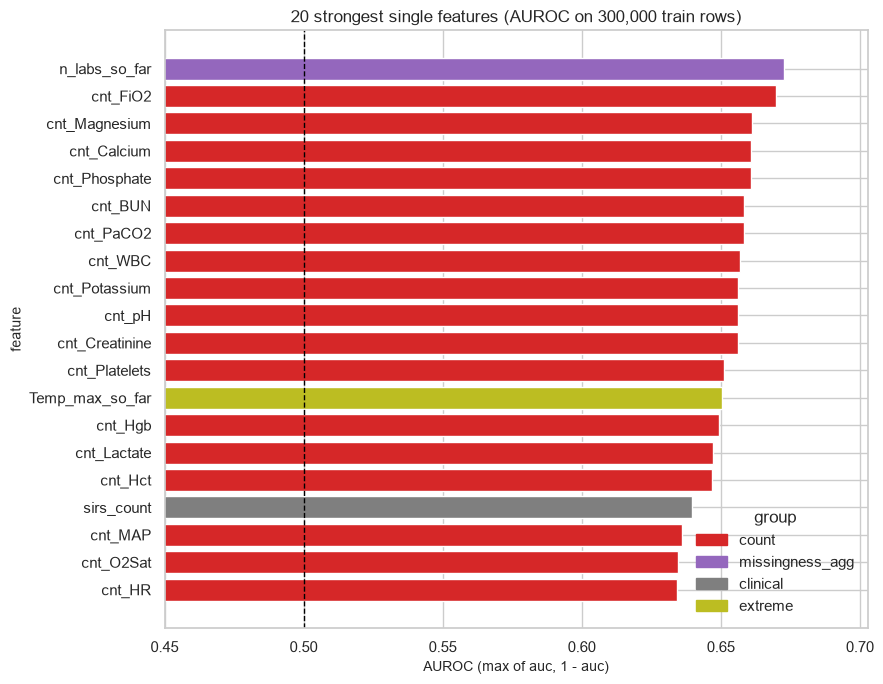

In [12]:
top = auc_table.head(20).iloc[::-1]
group_order = ["value", "mask", "time_since", "count", "missingness_agg", "rolling", "trend", "clinical", "extreme", "static"]
group_colors = dict(zip(group_order, sns.color_palette("tab10", len(group_order))))

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["feature"], top["auc"], color=[group_colors[g] for g in top["group"]])
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set_xlim(0.45, max(0.7, top["auc"].max() + 0.03))
ax.set(title="20 strongest single features (AUROC on 300,000 train rows)", xlabel="AUROC (max of auc, 1 - auc)", ylabel="feature")
present = [g for g in group_order if g in set(top["group"])]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=group_colors[g]) for g in present], present, title="group", loc="lower right")
save_fig("fig05_univariate_auroc_top20.png")

## Scaled table shift

Mean and standard deviation of the standardised columns on validation and test rows, as a carry-over from step 04.

In [13]:
STD_COLS = VALUE_COLS + ["Age", "HospAdmTime", "ICULOS"]
scaled_split = pd.read_parquet(SCALED_PATH, columns=["split"])["split"].to_numpy()
shift_rows = []
for col in STD_COLS:
    x = read_col(SCALED_PATH, col).astype("float64")
    row = {"column": col}
    for name in ("val", "test"):
        part = x[scaled_split == name]
        row[f"{name}_mean"], row[f"{name}_std"] = part.mean(), part.std()
        row[f"{name}_abs_std_dev"] = abs(row[f"{name}_std"] - 1)
    shift_rows.append(row)
shift = pd.DataFrame(shift_rows).set_index("column")
shift_path = TAB / "scaled_shift_val_test.csv"
shift.round(4).to_csv(shift_path)
SAVED.append(shift_path)

for name in ("val", "test"):
    log(f"{name}: five columns with the largest |std - 1|")
    log(shift[f"{name}_abs_std_dev"].nlargest(5).round(3).to_string())
    log(f"{name}: five columns with the largest |mean|")
    log(shift[f"{name}_mean"].abs().nlargest(5).round(3).to_string())

val: five columns with the largest |std - 1|
column
EtCO2              0.205
Bilirubin_direct   0.183
Phosphate          0.065
BUN                0.057
Bilirubin_total    0.048
val: five columns with the largest |mean|
column
Phosphate    0.032
Fibrinogen   0.026
EtCO2        0.025
FiO2         0.022
Platelets    0.020
test: five columns with the largest |std - 1|
column
EtCO2              0.232
Bilirubin_direct   0.070
Bilirubin_total    0.069
Fibrinogen         0.058
TroponinI          0.038
test: five columns with the largest |mean|
column
HospAdmTime   0.040
Potassium     0.036
Hct           0.030
Hgb           0.027
Lactate       0.026


## Output files

In [14]:
summary_path = TAB.parent / "step05_summary.txt"

log("")
log("saved files")
for path in SAVED:
    status = f"{file_mb(path):.2f} MB" if path.exists() else "MISSING"
    log(f"  {path.relative_to(ROOT)}  {status}")
log(f"  {summary_path.relative_to(ROOT)}  (this file)")

summary_path.write_text("\n".join(SUMMARY) + "\n")
print()
print(summary_path)


saved files
  data/processed/features_flat.parquet  184.22 MB
  results/tables/feature_catalog.csv  0.01 MB
  data/processed/feature_sets.json  0.01 MB
  results/tables/feature_nan_share.csv  0.01 MB
  results/tables/univariate_auroc_train.csv  0.01 MB
  results/figures/fig05_univariate_auroc_top20.png  0.09 MB
  results/tables/scaled_shift_val_test.csv  0.00 MB
  results/step05_summary.txt  (this file)

/Users/harnoorkaur/Downloads/Sepsis_ml/results/step05_summary.txt
